# 03 · XGBoost, class-imbalance strategies and a leakage check

**Goal:** beat the logistic-regression baseline with gradient-boosted trees, find
out which way of handling the 0.2% fraud rate works best, and check how much of
the performance depends on information a bank would not have at decision time.

- Models are **fitted on train** and **early-stopped on validation**.
- Strategies and hyperparameters are **chosen on validation PR-AUC**.
- The **test split is not used** in this notebook. Because validation is used for
  both early stopping and selection, validation scores here are slightly
  optimistic; the untouched test split gives the honest number at the end.

In [1]:
import sys
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_data
from src.features import filter_relevant, default_boundaries, time_split, build_features
from src.models import make_logreg_baseline
from src.evaluate import evaluate_model, plot_pr_curve, plot_confusion_matrix, save_metrics
from src.plotting import set_style
from src import train as tr

np.random.seed(tr.SEED)
set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print("xgboost version:", tr.check_xgboost_version())
print("early_stopping_rounds and eval_metric are passed to the XGBClassifier constructor (xgboost >= 2.0).")

xgboost version: 3.4.1
early_stopping_rounds and eval_metric are passed to the XGBClassifier constructor (xgboost >= 2.0).


## 1. Data, split and the two feature sets

In [2]:
df = load_data(money_dtype="float64")
df = filter_relevant(df, verbose=False)
train_end, val_end = default_boundaries(df["step"])
train, val, test = time_split(df, train_end, val_end)

n_test_rows = len(test)
del test, df   # the test split is not used in this notebook

y_train, y_val = train["isFraud"].astype(int), val["isFraud"].astype(int)
FEATURE_SETS = ["full", "pre_transaction"]
X = {fs: (build_features(train, feature_set=fs), build_features(val, feature_set=fs))
     for fs in FEATURE_SETS}
for fs in FEATURE_SETS:
    print(f"{fs:<16} {list(X[fs][0].columns)}")
print(f"\nscale_pos_weight (legit / fraud in train) = {tr.scale_pos_weight_value(y_train):,.1f}")

train steps   1-520  2,653,729 rows |  5,781 fraud | fraud rate 0.2178%
val   steps 521-632     78,709 rows |  1,188 fraud | fraud rate 1.5094%
test  steps 633-743     37,971 rows |  1,244 fraud | fraud rate 3.2762%


full             ['amount_log', 'errorBalanceOrig', 'errorBalanceDest', 'orig_emptied', 'dest_new_or_zero', 'hour', 'amount_to_balance_ratio', 'is_transfer']
pre_transaction  ['amount_log', 'oldbalanceOrg_log', 'oldbalanceDest_log', 'amount_to_balance_ratio', 'dest_new_or_zero', 'hour', 'is_transfer']

scale_pos_weight (legit / fraud in train) = 458.0


**Why two feature sets.** A first run with the **full** feature set (the one used
for the baseline) gave near-perfect validation scores for *every* model, which is
a warning sign. Two patterns in PaySim's post-transaction balances almost give
the label away (TRANSFER and CASH_OUT, training period):

| Pattern | Fraud | Legit |
|---|---|---|
| Origin balance adds up exactly (`errorBalanceOrig` = 0) | 99.4% | 9.4% |
| Destination never credited (balance stays 0 despite the transfer) | 49.4% | 0.06% |

Both use balances recorded **after** the transaction (`newbalanceOrig`,
`newbalanceDest`), and they reflect how the simulator books fraud rather than how
fraudsters behave. A bank scoring a payment at authorisation time would not have
the destination's updated balance.

- **full:** amount, balance errors, emptied/new-account flags, ratio, hour, type.
- **pre_transaction:** only what is known before the payment is processed:
  amount, opening balances of both accounts, amount-to-balance ratio,
  empty-destination flag, hour and type. **This is the realistic model and the
  headline result.**

## 2. Four ways to handle class imbalance

All four use the same starting hyperparameters (depth 6, learning rate 0.1, up to
1,000 trees with early stopping on validation PR-AUC), so only the imbalance
handling differs:

| Strategy | What it does |
|---|---|
| **none** | Train on the data as it is. |
| **scale_pos_weight** | Count each fraud row ~458 times as heavily in the loss. |
| **SMOTE** | Add synthetic fraud rows to the training set until fraud is 10% of legit. |
| **undersample** | Randomly drop legit rows from the training set until fraud is 10% of legit. |

Resampling is applied to the **training set only**; validation keeps its real
class mix.

In [3]:
strategy_results, strategy_models, strategy_scores = {}, {}, {}
for fs in FEATURE_SETS:
    print(f"Feature set: {fs}")
    X_tr, X_va = X[fs]
    strategy_results[fs], strategy_models[fs], strategy_scores[fs] = tr.compare_strategies(
        X_tr, y_train, X_va, y_val)

Feature set: full


  none              val PR-AUC 0.9992  (10s)


  scale_pos_weight  val PR-AUC 0.9999  (9s)


  smote             val PR-AUC 1.0000  (15s)


  undersample       val PR-AUC 1.0000  (2s)
Feature set: pre_transaction


  none              val PR-AUC 0.9945  (29s)


  scale_pos_weight  val PR-AUC 0.9942  (33s)


  smote             val PR-AUC 1.0000  (10s)


  undersample       val PR-AUC 1.0000  (3s)


In [4]:
print("Full feature set (uses post-transaction balances)")
display(strategy_results["full"])
print("Pre-transaction feature set (realistic)")
display(strategy_results["pre_transaction"])

Full feature set (uses post-transaction balances)


,train rows,train fraud share,trees,val PR-AUC,val ROC-AUC,precision @0.5,recall @0.5,false alarms @0.5,seconds
strategy,,,,,,,,,
none,2653729,0.0022,20,0.9992,0.9992,1.0000,0.9966,0,10
scale_pos_weight,2653729,0.0022,11,0.9999,1.0000,0.9992,0.9983,1,9
smote,2912742,0.0909,33,1.0000,1.0000,1.0000,0.9966,0,15
undersample,63591,0.0909,64,1.0000,1.0000,1.0000,0.9966,0,2


Pre-transaction feature set (realistic)


,train rows,train fraud share,trees,val PR-AUC,val ROC-AUC,precision @0.5,recall @0.5,false alarms @0.5,seconds
strategy,,,,,,,,,
none,2653729,0.0022,151,0.9945,0.9999,0.9924,0.8737,8,29
scale_pos_weight,2653729,0.0022,178,0.9942,0.9999,0.9102,0.9983,117,33
smote,2912742,0.0909,1,1.0000,1.0000,0.0000,0.0000,0,10
undersample,63591,0.0909,102,1.0000,1.0000,0.9966,1.0000,4,3


**How to read these tables:** PR-AUC measures how well each model *ranks* fraud
above legitimate transactions, independent of any threshold, so it decides the
winner. Precision and recall at 0.5 depend on how each strategy shifts the
predicted probabilities: weighting and resampling make the model believe fraud is
far more common than it is, which inflates scores, raises recall and lowers
precision at a fixed 0.5 cut-off. The threshold is chosen from costs in the next
notebook, so the @0.5 columns are for context only.

In [5]:
best_strategy = {fs: strategy_results[fs]["val PR-AUC"].idxmax() for fs in FEATURE_SETS}
for fs in FEATURE_SETS:
    print(f"{fs:<16} best strategy: {best_strategy[fs]} "
          f"(val PR-AUC {strategy_results[fs].loc[best_strategy[fs], 'val PR-AUC']:.4f})")

full             best strategy: undersample (val PR-AUC 1.0000)
pre_transaction  best strategy: smote (val PR-AUC 1.0000)


## 3. Hyperparameter search

For each feature set: a random search of up to 20 trials over `max_depth`,
`learning_rate`, `min_child_weight`, `subsample` and `colsample_bytree`, using
that set's best strategy. Every trial trains on the training split and is scored
on the validation split, so time order is preserved: there are no shuffled
cross-validation folds mixing earlier and later hours. Each search also stops
starting new trials after 15 minutes.

In [6]:
best_models, search_results, best_params = {}, {}, {}
for fs in FEATURE_SETS:
    print(f"\nFeature set: {fs} (strategy: {best_strategy[fs]})")
    X_tr, X_va = X[fs]
    t0 = time.time()
    best_models[fs], search_results[fs] = tr.random_search(
        X_tr, y_train, X_va, y_val, strategy=best_strategy[fs], n_trials=20, time_budget_s=900)
    params = search_results[fs].iloc[0][list(tr.SEARCH_SPACE)].to_dict()
    params["max_depth"] = int(params["max_depth"])
    params["n_estimators"] = int(best_models[fs].best_iteration) + 1
    best_params[fs] = params
    print(f"Search took {(time.time() - t0) / 60:.1f} minutes")


Feature set: full (strategy: undersample)


trial  1: val PR-AUC 0.9990 (1s, 6 trees)


trial  2: val PR-AUC 0.9984 (2s, 77 trees)


trial  3: val PR-AUC 0.9995 (2s, 60 trees)


trial  4: val PR-AUC 0.9999 (2s, 80 trees)


...

trial 16: val PR-AUC 1.0000 (50s, 342 trees)


trial 17: val PR-AUC 1.0000 (19s, 112 trees)


trial 18: val PR-AUC 1.0000 (7s, 3 trees)


trial 19: val PR-AUC 1.0000 (9s, 1 trees)


trial 20: val PR-AUC 1.0000 (10s, 7 trees)
Search took 4.3 minutes


In [7]:
print("Top 5 trials, pre-transaction feature set")
display(search_results["pre_transaction"].head(5))

best_scores, best_val = {}, {}
for fs in FEATURE_SETS:
    best_scores[fs] = best_models[fs].predict_proba(X[fs][1])[:, 1]
    best_val[fs] = evaluate_model(y_val, best_scores[fs], threshold=0.5)
    untuned = strategy_results[fs].loc[best_strategy[fs], "val PR-AUC"]
    print(f"{fs:<16} val PR-AUC untuned {untuned:.4f} -> tuned {best_val[fs]['pr_auc']:.4f} | "
          + ", ".join(f"{k}={round(v, 3) if isinstance(v, float) else v}" for k, v in best_params[fs].items()))

Top 5 trials, pre-transaction feature set


,trial,colsample_bytree,learning_rate,max_depth,min_child_weight,subsample,best_iteration,val_pr_auc,seconds
0,1,0.6873,0.2678,5,21.1189,0.8387,2,1.0000,8.5000
1,2,0.7229,0.0378,5,29.6215,0.8404,9,1.0000,9.0000
2,3,0.8540,0.0315,4,16.8521,0.9754,45,1.0000,12.8000
3,4,0.5004,0.2947,3,3.2877,0.8099,21,1.0000,9.7000
4,5,0.7160,0.0587,5,4.7792,0.6187,0,1.0000,8.3000


full             val PR-AUC untuned 1.0000 -> tuned 1.0000 | max_depth=8, learning_rate=0.061, min_child_weight=2.256, subsample=0.827, colsample_bytree=0.831, n_estimators=137
pre_transaction  val PR-AUC untuned 1.0000 -> tuned 1.0000 | max_depth=5, learning_rate=0.268, min_child_weight=21.119, subsample=0.839, colsample_bytree=0.687, n_estimators=3


## 4. Baselines vs XGBoost

In [8]:
logreg_scores, logreg_val = {}, {}
for fs in FEATURE_SETS:
    X_tr, X_va = X[fs]
    logreg_scores[fs] = make_logreg_baseline().fit(X_tr, y_train).predict_proba(X_va)[:, 1]
    logreg_val[fs] = evaluate_model(y_val, logreg_scores[fs], threshold=0.5)

cols = ["pr_auc", "roc_auc", "precision", "recall", "tp", "fp", "fn"]
comparison = pd.DataFrame({
    "logistic regression, full (notebook 02 baseline)": logreg_val["full"],
    "logistic regression, pre-transaction": logreg_val["pre_transaction"],
    f"XGBoost, full ({best_strategy['full']}, tuned)": best_val["full"],
    f"XGBoost, pre-transaction ({best_strategy['pre_transaction']}, tuned)": best_val["pre_transaction"],
}).T[cols]
print(f"Validation base rate {best_val['full']['base_rate']:.4%}; @0.5 columns at threshold 0.5")
comparison

Validation base rate 1.5094%; @0.5 columns at threshold 0.5


,pr_auc,roc_auc,precision,recall,tp,fp,fn
"logistic regression, full (notebook 02 baseline)",0.8786,0.9905,0.1794,0.9832,1168,5341,20
"logistic regression, pre-transaction",0.4341,0.9590,0.0872,0.9116,1083,11335,105
"XGBoost, full (undersample, tuned)",1.0000,1.0000,1.0000,0.9966,1184,0,4
"XGBoost, pre-transaction (smote, tuned)",1.0000,1.0000,1.0000,0.9983,1186,0,2


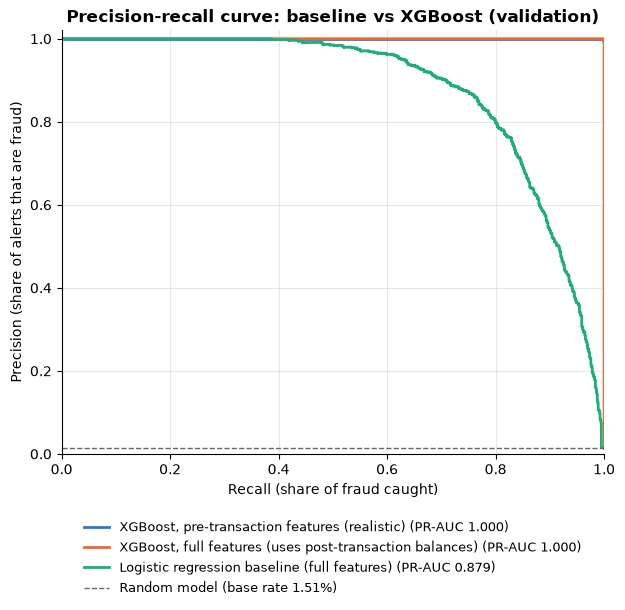

In [9]:
fig = plot_pr_curve(
    {"XGBoost, pre-transaction features (realistic)": (y_val, best_scores["pre_transaction"]),
     "XGBoost, full features (uses post-transaction balances)": (y_val, best_scores["full"]),
     "Logistic regression baseline (full features)": (y_val, logreg_scores["full"])},
    title="Precision-recall curve: baseline vs XGBoost (validation)",
    name="pr_curve_xgb_vs_baseline",
)
plt.show()

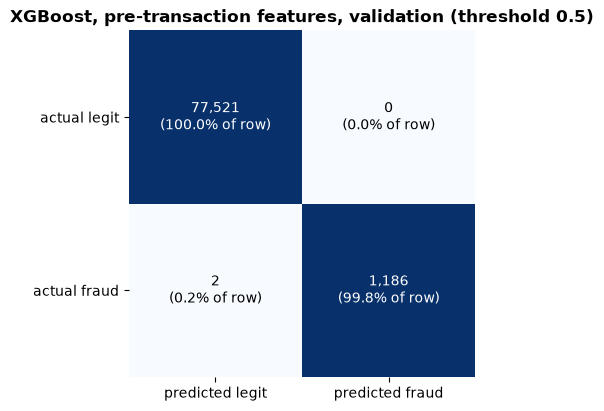

In [10]:
fig = plot_confusion_matrix(
    best_val["pre_transaction"]["confusion_matrix"],
    title="XGBoost, pre-transaction features, validation (threshold 0.5)",
    name="xgb_confusion_matrix",
)
plt.show()

## 5. Save the models and their settings

In [11]:
fixed = {"tree_method": "hist", "eval_metric": "aucpr",
         "early_stopping_rounds": tr.EARLY_STOPPING_ROUNDS, "seed": tr.SEED}
params_out = {"headline_model": "pre_transaction"}
for fs in FEATURE_SETS:
    path = tr.save_model(best_models[fs], f"xgb_{fs}")
    print(f"Saved {path.relative_to(ROOT)} (gitignored)")
    params_out[fs] = {
        "strategy": best_strategy[fs],
        "hyperparameters": best_params[fs],
        "fixed_settings": {**fixed, "resample_ratio": 0.1 if best_strategy[fs] in ("smote", "undersample") else None},
        "features": list(X[fs][0].columns),
    }
save_metrics(params_out, ROOT / "reports" / "xgb_best_params.json")

save_metrics(
    {
        "note": "Validation scores; validation was used for early stopping and selection, "
                "so they are slightly optimistic. Test split not used.",
        "split": {"train_steps": [int(train["step"].min()), int(train_end)],
                  "val_steps": [int(train_end) + 1, int(val_end)],
                  "test_rows_not_used": int(n_test_rows)},
        "strategy_comparison": {fs: strategy_results[fs].reset_index().to_dict(orient="records")
                                for fs in FEATURE_SETS},
        "search_trials": {fs: search_results[fs].to_dict(orient="records") for fs in FEATURE_SETS},
        "validation": {f"logistic_regression_{fs}": logreg_val[fs] for fs in FEATURE_SETS}
                      | {f"xgboost_{fs}": best_val[fs] for fs in FEATURE_SETS},
    },
    ROOT / "reports" / "xgb_metrics.json",
)
print("Saved reports/xgb_best_params.json and reports/xgb_metrics.json")

Saved models\xgb_full.joblib (gitignored)
Saved models\xgb_pre_transaction.joblib (gitignored)
Saved reports/xgb_best_params.json and reports/xgb_metrics.json


## Summary

**Which strategy won?** None, in any meaningful sense. With the realistic
pre-transaction features, SMOTE and undersampling both reach validation PR-AUC
1.0000, while no handling (0.9945) and `scale_pos_weight` (0.9942) are a hair
behind. SMOTE was selected only because it comes first among the ties, and its
model reached that score with a **single tree**. The hyperparameter search gave
1.0000 for all 20 trials, and the chosen model uses just 3 trees. When every
option scores at the ceiling, the comparison cannot tell strategies apart.

The one practical difference is cost: **undersampling trains on 63,591 rows
instead of 2.65 million, in 3 seconds instead of about 30**, for the same score.
When the signal is this clean, discarding 98% of legitimate rows loses nothing.

**Why everything scores 1.0: PaySim fraud is close to a deterministic rule.**
Checked directly on the data (TRANSFER and CASH_OUT):

| Rule | Fraud | Legit |
|---|---|---|
| Amount equals the entire origin balance, or a capped 10M chunk of it (train) | 99.3% | 0 of 2.65M |
| Same rule (validation) | 99.75% | 0 of 77,521 |

In the simulator, a fraudster always **empties the account**: the transfer is
exactly the full opening balance, split into 10M chunks when larger. Not a single
legitimate transaction does this. Any model that sees the amount next to the
opening balance (here through `amount_to_balance_ratio`) finds this rule with one
split, which is why one tree is enough. Removing the post-transaction balances
removed the bookkeeping artefacts, but not this one, because it is part of how
PaySim defines fraud.

**What this means:**

- A one-line rule matches XGBoost on PaySim. The models are "right", but there
  is almost nothing left for machine learning to learn.
- Logistic regression on the same pre-transaction features scores only 0.434,
  because a linear model cannot express "ratio is *exactly* 1"; trees can.
- Real fraud is not this clean: legitimate customers sometimes move their whole
  balance, and fraudsters do not always take all of it. These scores should not
  be read as what a bank could expect.
- The imbalance strategies, the threshold choice and explainability all become
  trivial at a perfect ranking, so the project needs a decision on how to
  continue before those steps.